# F23: Endelig volum-metode i 1D -- en stav uten kildeledd

Denne notatboken hører til **F23** og kompendiets §3.4 («Numeriske metoder: Endeligvolum-metode») og eksempel 3.12 i §3.5 («Varmeledning i en stav uten kildeledd»). Koden er skrevet på samme måte som i øvingene, så du kan bruke den direkte som mal.

Ideen i endelig volum-metoden (EVM) er å skrive opp **bevaringsloven for hvert kontrollvolum**: varmen som strømmer inn gjennom kontrollvolumets flater, minus varmen som strømmer ut, er lik varmen som produseres inne i det. For en stav uten varmekilde betyr det bare at *fluksen inn = fluksen ut*. Diskretisert gir det én ligning per node,
$$
a_P u_P = a_W u_W + a_E u_E + S^u, \qquad a_P = a_W + a_E - S_P,
$$
og et tridiagonalt ligningssystem $L\,u = F$ som vi løser med `la.solve(L, F)`.

In [1]:
import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt

## 1. Problemet

Eksempel 3.12: en stav med lengde $R=0.5$ m, varmeledningsevne $k = 1000$ W/(m K) og tverrsnittsareal $A = 10\cdot 10^{-3}$ m$^2$, slik at $kA = 10$. Venstre ende holdes på $T_V = 100\,^\circ$C og høyre ende på $T_H = 500\,^\circ$C. Det er ingen varmekilde, så temperaturen $u(x)$ oppfyller
$$
\frac{d}{dx}\left(kA \frac{du}{dx}\right) = 0, \qquad u(0)=T_V, \quad u(R)=T_H .
$$
Den eksakte løsningen er en rett linje, $u(x) = T_V + (T_H-T_V)\,x/R = 100 + 800x$.

In [2]:
R = 0.5          # lengde på staven [m]
kA = 10          # termisk ledningsevne * areal på tverrsnitt [W m/K]
a = 100          # T_V: temperaturen i venstre ende [grader C]
b = 500          # T_H: temperaturen i høyre ende [grader C]

def u_eksakt(x):
    return a + (b - a) * x / R

## 2. Rutenettgenerering: punktene

Vi deler staven i $m=5$ like store kontrollvolum med bredde $\delta x = 0.1$ m. Nodene -- der vi regner ut temperaturen -- ligger **midt i** hvert kontrollvolum, i $x = 0.05, 0.15, \ldots, 0.45$. Randene $V$ og $H$ er flater, ikke noder.

Som i øvingene samler vi alle punktene i én vektor `x`, med randpunktene først og sist:
$$
x = [\,0,\; 0.05,\; 0.15,\; 0.25,\; 0.35,\; 0.45,\; 0.5\,] .
$$
De ukjente er temperaturene i de **indre** punktene `x[1:-1]`. Avstandene mellom nabopunkter er `dx = x[1:] - x[:-1]`. Legg merke til at den første og siste avstanden bare er $\delta x/2 = 0.05$: den ytterste noden ligger en *halv* celle fra randen.

x  = [0.   0.05 0.15 0.25 0.35 0.45 0.5 ]
dx = [0.05 0.1  0.1  0.1  0.1  0.05]


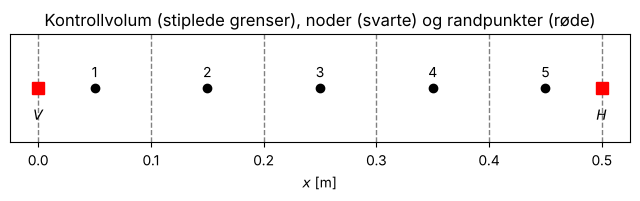

In [3]:
# Rutenettgenerering
m = 5                                         # antall kontrollvolum (= antall ukjente)
deltax = R / m
x = np.zeros(m + 2)
x[1:-1] = deltax / 2 + deltax * np.arange(m)  # nodene, midt i hvert kontrollvolum
x[-1] = R                                     # randpunktene: x[0] = 0 og x[-1] = R
dx = x[1:] - x[:-1]                           # avstand mellom nabopunkter

print("x  =", x)
print("dx =", dx)

flater = np.linspace(0, R, m + 1)
fig, ax = plt.subplots(figsize=(8, 1.4))
for xf in flater:
    ax.axvline(xf, color="gray", ls="--", lw=1)
ax.plot(x[1:-1], np.zeros(m), "ko")
for i, xn in enumerate(x[1:-1]):
    ax.annotate(f"{i+1}", (xn, 0), textcoords="offset points", xytext=(0, 8), ha="center")
ax.plot([0, R], [0, 0], "rs", ms=8)
ax.text(0, -0.6, "$V$", ha="center"); ax.text(R, -0.6, "$H$", ha="center")
ax.set_ylim(-1, 1); ax.set_yticks([]); ax.set_xlabel("$x$ [m]")
ax.set_title("Kontrollvolum (stiplede grenser), noder (svarte) og randpunkter (røde)")
plt.show()

## 3. Diskretisering: koeffisientene

Integrerer vi ligningen over kontrollvolumet rundt node $P$ og tilnærmer fluksene lineært mellom nabopunktene, får vi
$$
a_W = \frac{kA}{\delta x_{WP}}, \qquad a_E = \frac{kA}{\delta x_{PE}}, \qquad a_P = a_W + a_E ,
$$
der $\delta x_{WP}$ og $\delta x_{PE}$ er avstandene til nabopunktene -- altså elementene i `dx`.

For node 1 er vestnaboen selve **randpunktet** $V$, med kjent temperatur $T_V$, i avstand `dx[0]` $=\delta x/2$. Leddet $a_W T_V$ er kjent og flyttes over til høyresiden. Tilsvarende for node 5 og $T_H$.

> **Sammenheng med kompendiet:** I kompendiet «kuttes koblingen» ($a_W = 0$) og randen legges i kildeleddet: $S^u = \frac{2kA}{\delta x}T_V$, $S_P = -\frac{2kA}{\delta x}$. Siden `dx[0]` $= \delta x/2$, er $\frac{kA}{\texttt{dx[0]}} = \frac{2kA}{\delta x}$ -- det er nøyaktig det samme. Diagonalen blir $a_P = a_E - S_P$ i begge tilfeller.

In [4]:
# Diskretisering (som i øvingen)
koeff_diag  = kA * (1 / dx[:-1] + 1 / dx[1:])   # a_P = a_W + a_E
koeff_over  = -kA / dx[1:-1]                     # -a_E (kobling til østnaboen)
koeff_under = -kA / dx[1:-1]                     # -a_W (kobling til vestnaboen)

L = np.diag(koeff_over, 1) + np.diag(koeff_under, -1) + np.diag(koeff_diag, 0)

F = np.zeros((m))
F[0]  = kA * 1 / dx[0] * a      # kjent randtemperatur til venstre
F[-1] = kA * 1 / dx[-1] * b     # kjent randtemperatur til høyre

print("L =\n", L)
print("F =", F)

L =
 [[ 300. -100.    0.    0.    0.]
 [-100.  200. -100.    0.    0.]
 [   0. -100.  200. -100.    0.]
 [   0.    0. -100.  200. -100.]
 [   0.    0.    0. -100.  300.]]
F = [ 20000.      0.      0.      0. 100000.]


Sammenlign med tabellen i kompendiet: $a_P = 300$ i randnodene og $200$ i de indre, $-100$ utenfor diagonalen, og høyresiden $200\,T_V = 20000$ og $200\,T_H = 100000$.

## 4. Løsning til lineært system

Numerisk løsning: [140. 220. 300. 380. 460.]
Eksakt i nodene:   [140. 220. 300. 380. 460.]


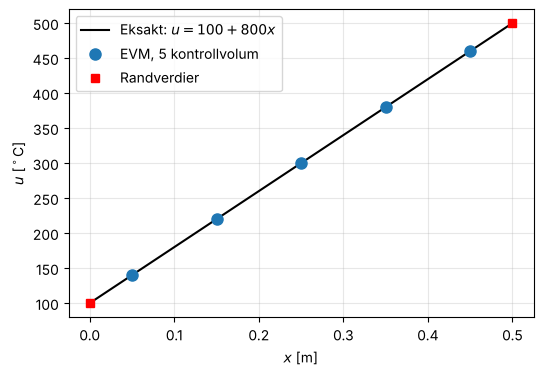

In [5]:
u = la.solve(L, F)
print("Numerisk løsning:", u)
print("Eksakt i nodene:  ", u_eksakt(x[1:-1]))

x_fin = np.linspace(0, R, 200)
plt.figure(figsize=(6, 4))
plt.plot(x_fin, u_eksakt(x_fin), "k-", label="Eksakt: $u=100+800x$")
plt.plot(x[1:-1], u, "o", ms=8, label="EVM, 5 kontrollvolum")
plt.plot([0, R], [a, b], "rs", label="Randverdier")
plt.xlabel("$x$ [m]"); plt.ylabel(r"$u$ [$^\circ$C]")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

Den numeriske løsningen er **eksakt** i nodene: $140, 220, 300, 380, 460$. Det er ikke tilfeldig -- vi har tilnærmet fluksene med rette linjer mellom nabopunktene, og det er eksakt når temperaturen selv er en rett linje.

## 5. Bevaring: den samme varmen strømmer gjennom hver flate

Uten varmekilde må like mye varme strømme gjennom *hver* flate (stasjonært tilfelle) i staven (ellers ville et kontrollvolum samle opp eller miste varme). Varmefluksen i $x$-retning er $Q = -kA\,\dfrac{du}{dx}$; her er den eksakt
$$
Q = -kA \cdot 800 = -8000 \text{ W},
$$
altså 8 kW fra den varme høyre enden mot den kalde venstre.

I EVM regner vi fluksen mellom to nabopunkter ut med *samme* formel som vi brukte da vi satte opp ligningene. Legger vi randverdiene til løsningen, får vi fluksen gjennom alle seks flatene på én linje:

In [6]:
U = np.zeros(m + 2)
U[0], U[1:-1], U[-1] = a, u, b          # løsningen med randverdiene

Q = -kA * (U[1:] - U[:-1]) / dx          # fluks mellom hvert par av nabopunkter [W]
for xa, xb, q in zip(x[:-1], x[1:], Q):
    print(f"Mellom x = {xa:.2f} og {xb:.2f} m:  Q = {q:8.1f} W")

Mellom x = 0.00 og 0.05 m:  Q =  -8000.0 W
Mellom x = 0.05 og 0.15 m:  Q =  -8000.0 W
Mellom x = 0.15 og 0.25 m:  Q =  -8000.0 W
Mellom x = 0.25 og 0.35 m:  Q =  -8000.0 W
Mellom x = 0.35 og 0.45 m:  Q =  -8000.0 W
Mellom x = 0.45 og 0.50 m:  Q =  -8000.0 W


Alle flatene har samme fluks, $-8000$ W. Det er dette som menes med at EVM er **konservativ**: fluksen ut av ett kontrollvolum er *per konstruksjon* fluksen inn i naboen, så det som går inn i den ene enden kommer ut i den andre -- uansett hvor grovt gitteret er.

## 6. Punktene trenger ikke ligge jevnt

Ingenting i koden over krever at punktene ligger med lik avstand: koeffisientene er bare $kA$ delt på avstanden til naboen. Vi kan derfor like gjerne velge tilfeldige punkter (sortert, og med randpunktene med):

dx = [0.10726691 0.00555853 0.22870116 0.07650616 0.00813477 0.07383247]
Maks avvik fra eksakt løsning: 6.821210263296962e-13


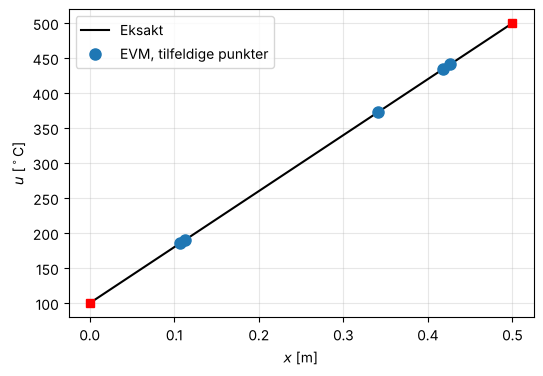

In [7]:
m = 5
x = np.random.rand(m + 2) * R
x = np.sort(x)
x[0]  = 0
x[-1] = R
dx = x[1:] - x[:-1]
print("dx =", dx)

L = kA * (-np.diag((1 / dx)[1:-1], 1) - np.diag(1 / dx[1:-1], -1)
          + np.diag(1 / dx[1:], 0) + np.diag(1 / dx[:-1], 0))
F = np.zeros((m))
F[0]  = kA * 1 / dx[0] * a
F[-1] = kA * 1 / dx[-1] * b

u = la.solve(L, F)
print("Maks avvik fra eksakt løsning:", np.max(np.abs(u - u_eksakt(x[1:-1]))))

plt.figure(figsize=(6, 4))
plt.plot(x_fin, u_eksakt(x_fin), "k-", label="Eksakt")
plt.plot(x[1:-1], u, "o", ms=8, label="EVM, tilfeldige punkter")
plt.plot([0, R], [a, b], "rs")
plt.xlabel("$x$ [m]"); plt.ylabel(r"$u$ [$^\circ$C]"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

Matrisen `L` er her skrevet på én linje, slik den også står i øvingene: diagonalen er $kA\,(1/\texttt{dx[:-1]} + 1/\texttt{dx[1:]})$, og elementene rett over og under diagonalen er $-kA/\texttt{dx[1:-1]}$. Løsningen er fortsatt eksakt, fordi den eksakte løsningen er lineær.

> **Like store avstander:** Velger vi punktene jevnt, `x = np.linspace(0, R, m+2)`, er alle elementene i `dx` like ($=h$). Da er `L` nøyaktig $kA\,h$ ganger matrisen fra differansemetoden for $u''=0$, og vi får **samme løsning** som med endelige differanser (F20).

## 7. Utblikk: en stav av to materialer

For konstant $k$ gir EVM og endelige differanser de samme ligningene (se bemerkningen i kompendiet). Fordelen med EVM viser seg når $k$ *varierer*. Tenk deg en vegg av to lag: venstre halvdel har $k_1 = 1000$ W/(m K), høyre halvdel $k_2 = 100$ W/(m K).

Den eksakte løsningen er stykkevis lineær. Varmen må passere begge lagene etter hverandre, akkurat som strøm gjennom to seriekoblede motstander:
$$
Q = -\frac{T_H - T_V}{R_1 + R_2}, \qquad R_j = \frac{R/2}{k_j A}.
$$

I koden lar vi nå `kA` være én verdi **per intervall** mellom to nabopunkter (like lang som `dx`). Formlene er ellers uendret -- vi bytter bare `kA` med `kAi`. Spørsmålet er hvilken verdi intervallet som krysser grenseflaten skal få: gjennomsnittet av verdiene i de to endepunktene (aritmetisk middel), eller det harmoniske middelet?

Eksakt fluks: Q = -1454.5 W, grensetemperatur 136.36 C
Maks feil, aritmetisk middel: 23.480151380948712
Maks feil, harmonisk middel:  1.7053025658242404e-13


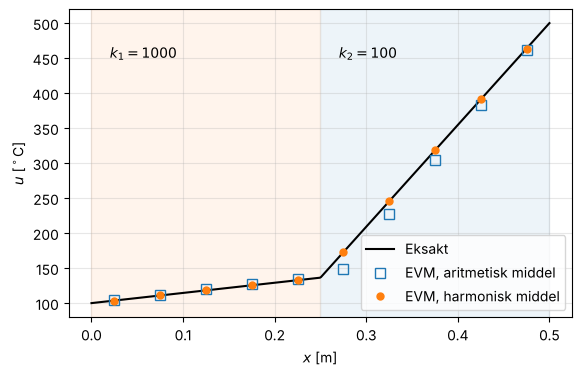

In [8]:
A = 10e-3
k1, k2 = 1000.0, 100.0
k_to = lambda x: np.where(x < R / 2, k1, k2)

R1 = (R / 2) / (k1 * A); R2 = (R / 2) / (k2 * A)
Q_eks = -(b - a) / (R1 + R2)
T_grense = a - Q_eks * R1                # temperaturen i grenseflaten x = R/2
def u_to_eksakt(x):
    return np.where(x < R / 2,
                    a + (T_grense - a) * x / (R / 2),
                    T_grense + (b - T_grense) * (x - R / 2) / (R / 2))

def evm_1d(x, kA_punkt, a, b, middel="aritmetisk"):
    '''EVM for d/dx(kA du/dx) = 0 med kjente randverdier a og b.
    x: alle punkter inkludert randpunktene, kA_punkt: kA i hvert punkt.
    Returnerer løsningen i de indre punktene.'''
    m = len(x) - 2
    dx = x[1:] - x[:-1]
    if middel == "aritmetisk":
        kAi = 0.5 * (kA_punkt[:-1] + kA_punkt[1:])                          # kA per intervall
    else:
        kAi = 2 * kA_punkt[:-1] * kA_punkt[1:] / (kA_punkt[:-1] + kA_punkt[1:])
    L = (-np.diag((kAi / dx)[1:-1], 1) - np.diag((kAi / dx)[1:-1], -1)
         + np.diag((kAi / dx)[1:], 0) + np.diag((kAi / dx)[:-1], 0))
    F = np.zeros((m))
    F[0]  = kAi[0] / dx[0] * a
    F[-1] = kAi[-1] / dx[-1] * b
    return la.solve(L, F)

# 10 kontrollvolum, nodene midt i hvert; grenseflaten x = R/2 er en flate midt mellom to noder
m = 10
deltax = R / m
x = np.zeros(m + 2); x[1:-1] = deltax / 2 + deltax * np.arange(m); x[-1] = R
kA_punkt = k_to(x) * A

u_a = evm_1d(x, kA_punkt, a, b, middel="aritmetisk")
u_h = evm_1d(x, kA_punkt, a, b, middel="harmonisk")
print(f"Eksakt fluks: Q = {Q_eks:.1f} W, grensetemperatur {T_grense:.2f} C")
print("Maks feil, aritmetisk middel:", np.max(np.abs(u_a - u_to_eksakt(x[1:-1]))))
print("Maks feil, harmonisk middel: ", np.max(np.abs(u_h - u_to_eksakt(x[1:-1]))))

xx = np.linspace(0, R, 400)
plt.figure(figsize=(6.5, 4))
plt.axvspan(0, R/2, color="tab:orange", alpha=0.08); plt.axvspan(R/2, R, color="tab:blue", alpha=0.08)
plt.plot(xx, u_to_eksakt(xx), "k-", label="Eksakt")
plt.plot(x[1:-1], u_a, "s", ms=7, mfc="none", label=r"EVM, aritmetisk middel")
plt.plot(x[1:-1], u_h, "o", ms=5, label=r"EVM, harmonisk middel")
plt.text(0.02, 450, r"$k_1=1000$"); plt.text(0.27, 450, r"$k_2=100$")
plt.xlabel("$x$ [m]"); plt.ylabel(r"$u$ [$^\circ$C]"); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.show()

Med aritmetisk middel blir det en feil rundt grenseflaten. Med **harmonisk middel**,
$$
(kA)_e = \frac{2\,(kA)_P\,(kA)_E}{(kA)_P+(kA)_E},
$$
blir løsningen eksakt. Grunnen er at fluksen mellom $P$ og $E$ må gjennom to halve celler med ulik ledningsevne -- to seriekoblede «varmemotstander» $\frac{\delta x/2}{k_P A}$ og $\frac{\delta x/2}{k_E A}$ -- og summen av dem gir nettopp det harmoniske middelet. Dette er typisk for EVM: når vi tenker i *flukser over flater*, får vi et naturlig svar på hvordan materialegenskapene skal håndteres.

(Til vanlig holder det med aritmetisk middel, som i kompendiet.)

## Prøv selv

1. Øk antall kontrollvolum $m$ i stav-eksempelet. Er løsningen fortsatt eksakt? Hvorfor?
2. Bytt om randtemperaturene ($a = 500$, $b = 100$). Hva skjer med fortegnet til fluksen $Q$?
3. Bruk $m=9$ (oddetall) for staven av to materialer. Nå ligger grenseflaten *midt i* et kontrollvolum. Hvordan går det med de to middelverdiene da?
4. Utvid koden slik at den også tar et kildeledd (konstante $S^u$ og $S_P$ per node). Det er utgangspunktet for F24.

## Oppsummering

* EVM: del området i kontrollvolum, integrer ligningen over hvert av dem, og skriv om volumintegralet av divergensen til flukser over flatene (divergenssetningen).
* Tilnærm fluksene lineært mellom nabopunktene: $a_W = kA/\delta x_{WP}$, $a_E = kA/\delta x_{PE}$, $a_P = a_W + a_E - S_P$.
* I koden: punktene `x` (med randpunktene), `dx = x[1:] - x[:-1]`, matrisen `L` og høyresiden `F`, og `u = la.solve(L, F)`.
* Randverdier: randpunktet er en nabo i avstand `dx[0]` $=\delta x/2$; leddet flyttes til `F`.
* Metoden er konservativ: fluksen ut av ett kontrollvolum er fluksen inn i det neste.